# Лабораторная работа №4 — прогноз временного ряда NASA SMAP с LSTM

**Цель:** подготовить многомерный временной ряд, обучить LSTM прогнозировать следующий вектор из 25 каналов и оценить качество прогноза на тестовых данных.

Этапы: установка зависимостей, обзор данных, предобработка, формирование последовательностей, обучение, расчёт метрик и визуализация прогноза.

## Установка библиотек

В PowerShell из папки лабораторной выполните `python -m pip install -r requirements.txt`. Если используется виртуальное окружение, сначала активируйте его. В VS Code выберите это же окружение как Kernel ноутбука. Если зависимости уже установлены, этот шаг можно пропустить.

При необходимости установить пакеты из самого ноутбука запустите следующую ячейку один раз.

In [1]:
from pathlib import Path
import os
import sys

os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'
cwd = Path.cwd()
candidates = [cwd, *cwd.parents, cwd / 'ProjectWorl' / 'Labs' / 'Lab_04_LSTM_TimeSeries']
LAB_DIR = next((p.resolve() for p in candidates if (p / 'src' / 'smap_lstm').is_dir()), None)
if LAB_DIR is None:
    raise FileNotFoundError('Не найдена папка Lab_04_LSTM_TimeSeries. Откройте ноутбук из папки лабораторной.')
sys.path.insert(0, str(LAB_DIR / 'src'))
print('Папка лабораторной:', LAB_DIR)

Папка лабораторной: D:\Univer\neiry\lab1\ProjectWorl\Labs\Lab_04_LSTM_TimeSeries


In [2]:
# Запустить при отсутствии библиотек; после успешной установки перезапустить Kernel.
%pip install -r {LAB_DIR / 'requirements.txt'}

  Using cached pyyaml-6.0.3-cp314-cp314-win_amd64.whl.metadata (2.4 kB)
   ---------------------------------------- 0.0/11.1 MB ? eta -:--:--
   ---------------------------------------- 0.0/11.1 MB ? eta -:--:--
   ---------------------------------------- 0.0/11.1 MB ? eta -:--:--
   ---------------------------------------- 0.0/11.1 MB ? eta -:--:--
   ---------------------------------------- 0.0/11.1 MB ? eta -:--:--
   ---------------------------------------- 0.0/11.1 MB ? eta -:--:--
    --------------------------------------- 0.3/11.1 MB ? eta -:--:--
    --------------------------------------- 0.3/11.1 MB ? eta -:--:--
    --------------------------------------- 0.3/11.1 MB ? eta -:--:--
    --------------------------------------- 0.3/11.1 MB ? eta -:--:--
    --------------------------------------- 0.3/11.1 MB ? eta -:--:--
   - -------------------------------------- 0.5/11.1 MB 259.0 kB/s eta 0:00:41
   - -------------------------------------- 0.5/11.1 MB 259.0 kB/s eta 0:00:41



[notice] A new release of pip is available: 25.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


## 1. Загрузка и описание набора данных

Используются официальные файлы THULab/NASA SMAP. Обучающая выборка содержит нормальные наблюдения, а тестовая — метки аномалий. Каждая строка описывает 25 каналов телеметрии.

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf

from smap_lstm.data import describe_raw_data, load_dataset, prepare_dataset
from smap_lstm.model import build_lstm_model

SEED = 42
np.random.seed(SEED)
tf.keras.utils.set_random_seed(SEED)
print('TensorFlow:', tf.__version__)

DATA_DIR = LAB_DIR / 'data' / 'raw'
raw = load_dataset(DATA_DIR)
pd.Series(describe_raw_data(raw), name='Значение').to_frame()

TensorFlow: 2.22.0-rc0


,Значение
train_shape,"(135183, 25)"
test_shape,"(427617, 25)"
dtype,float32
features,25
feature_names,"[channel_0, channel_1, channel_2, channel_3, c..."
train_missing_or_infinite,0
test_missing_or_infinite,0
train_anomalies,0
test_anomalies,54696
time_step_ms,1000


## 2. Предобработка и оконные последовательности

Пропуски заполняются медианой, а каналы стандартизируются. Параметры заполнения и масштабирования вычисляются только на обучающей части. LSTM получает окно из 100 прошлых измерений и прогнозирует все каналы на следующем шаге.

In [4]:
WINDOW = 100
prepared = prepare_dataset(
    data_dir=DATA_DIR,
    window_size=WINDOW,
    validation_fraction=0.2,
    raw_data=raw,
)

for name in ('X_train', 'y_train', 'X_val', 'y_val', 'X_test', 'y_test'):
    print(f'{name:8s}: {getattr(prepared, name).shape}')
print('Размер входного окна:', WINDOW)
print('Число каналов:', len(prepared.feature_names))

X_train : (108046, 100, 25)
y_train : (108046, 25)
X_val   : (26937, 100, 25)
y_val   : (26937, 25)
X_test  : (427517, 100, 25)
y_test  : (427517, 25)
Размер входного окна: 100
Число каналов: 25


## 3. Архитектура LSTM

Модель состоит из двух LSTM-слоёв с Dropout и полносвязного выхода. Функция потерь — MSE, оптимизатор — Adam.

In [5]:
model = build_lstm_model(WINDOW, prepared.X_train.shape[-1])
model.summary()

Model: "smap_lstm_forecaster"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 100, 64)        │        23,040 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 100, 64)        │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 32)             │        12,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 16)             │           528 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 25)             │           425 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 36,409 (142.22 KB)

 Trainable params: 36,409 (142.22 KB)

 Non-trainable params: 0 (0.00 B)

## 4. Обучение

Оконные массивы SMAP велики, поэтому последовательности передаются модели небольшими батчами. Обучение остановится, если ошибка на валидации перестанет улучшаться.

In [6]:
import math

class BatchSequence(tf.keras.utils.Sequence):
    def __init__(self, X, y, batch_size=128, shuffle=False):
        super().__init__()
        self.X = X
        self.y = y
        self.batch_size = batch_size
        self.shuffle = shuffle
        self.order = np.arange(len(X))
        self.on_epoch_end()

    def __len__(self):
        return math.ceil(len(self.order) / self.batch_size)

    def __getitem__(self, batch_index):
        indices = self.order[batch_index * self.batch_size:(batch_index + 1) * self.batch_size]
        return (
            np.asarray(self.X[indices], dtype=np.float32),
            np.asarray(self.y[indices], dtype=np.float32),
        )

    def on_epoch_end(self):
        if self.shuffle:
            np.random.shuffle(self.order)

train_batches = BatchSequence(prepared.X_train, prepared.y_train, shuffle=True)
val_batches = BatchSequence(prepared.X_val, prepared.y_val)
results_dir = LAB_DIR / 'results'
results_dir.mkdir(exist_ok=True)

callbacks = [
    tf.keras.callbacks.EarlyStopping(
        monitor='val_loss', patience=3, restore_best_weights=True
    ),
    tf.keras.callbacks.ModelCheckpoint(
        results_dir / 'best_model.keras', monitor='val_loss', save_best_only=True
    ),
]

history = model.fit(
    train_batches,
    validation_data=val_batches,
    epochs=10,
    callbacks=callbacks,
    verbose=1,
)

Epoch 1/10
845/845 ━━━━━━━━━━━━━━━━━━━━ 71s 82ms/step - loss: 0.7984 - mae: 0.1496 - val_loss: 0.3182 - val_mae: 0.0810
Epoch 2/10
845/845 ━━━━━━━━━━━━━━━━━━━━ 56s 66ms/step - loss: 0.7499 - mae: 0.1186 - val_loss: 0.3138 - val_mae: 0.0738
Epoch 3/10
845/845 ━━━━━━━━━━━━━━━━━━━━ 50s 59ms/step - loss: 0.7412 - mae: 0.1139 - val_loss: 0.3108 - val_mae: 0.0767
Epoch 4/10
845/845 ━━━━━━━━━━━━━━━━━━━━ 51s 60ms/step - loss: 0.7316 - mae: 0.1133 - val_loss: 0.3034 - val_mae: 0.0758
Epoch 5/10
845/845 ━━━━━━━━━━━━━━━━━━━━ 51s 60ms/step - loss: 0.7227 - mae: 0.1130 - val_loss: 0.3024 - val_mae: 0.0758
Epoch 6/10
845/845 ━━━━━━━━━━━━━━━━━━━━ 51s 60ms/step - loss: 0.7147 - mae: 0.1122 - val_loss: 0.2941 - val_mae: 0.0768
Epoch 7/10
845/845 ━━━━━━━━━━━━━━━━━━━━ 59s 69ms/step - loss: 0.7053 - mae: 0.1119 - val_loss: 0.2877 - val_mae: 0.0748
Epoch 8/10
845/845 ━━━━━━━━━━━━━━━━━━━━ 52s 61ms/step - loss: 0.6983 - mae: 0.1130 - val_loss: 0.2846 - val_mae: 0.0712
Epoch 9/10
845/845 ━━━━━━━━━━━━━━━━━━━━ 

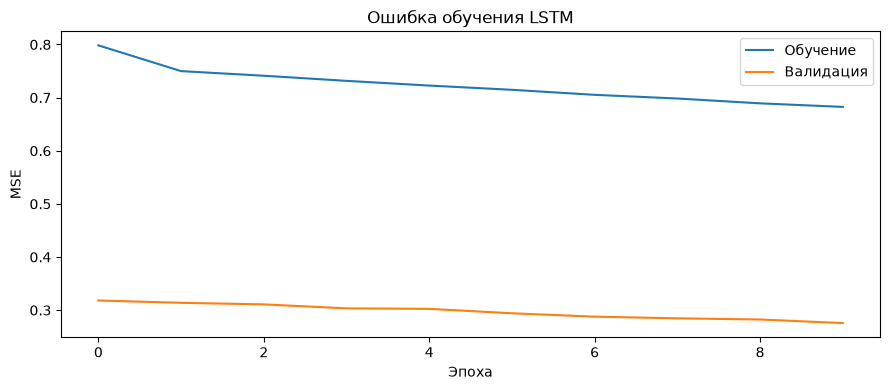

In [7]:
plt.figure(figsize=(9, 4))
plt.plot(history.history['loss'], label='Обучение')
plt.plot(history.history['val_loss'], label='Валидация')
plt.xlabel('Эпоха')
plt.ylabel('MSE')
plt.title('Ошибка обучения LSTM')
plt.legend()
plt.tight_layout()
plt.savefig(results_dir / 'training_loss.png', dpi=150)
plt.show()

## 5. Тестирование и метрики

Рассчитываются MAE и RMSE после обратного преобразования из стандартизированного масштаба. Это делает метрики понятными в исходных единицах каналов.

In [8]:
test_batches = BatchSequence(prepared.X_test, prepared.y_test)
print('Метрики в стандартизированном масштабе:', model.evaluate(test_batches, return_dict=True, verbose=1))

pred_scaled = model.predict(test_batches, verbose=1)
actual = prepared.scaler.inverse_transform(prepared.y_test)
predicted = prepared.scaler.inverse_transform(pred_scaled)

mae = float(np.mean(np.abs(actual - predicted)))
rmse = float(np.sqrt(np.mean((actual - predicted) ** 2)))
metrics = pd.DataFrame({'metric': ['MAE', 'RMSE'], 'value': [mae, rmse]})
display(metrics)
metrics.to_csv(results_dir / 'test_metrics.csv', index=False)

3340/3340 ━━━━━━━━━━━━━━━━━━━━ 97s 29ms/step - loss: 0.6251 - mae: 0.0717
Метрики в стандартизированном масштабе: {'loss': 0.6251000761985779, 'mae': 0.07168564200401306}
3340/3340 ━━━━━━━━━━━━━━━━━━━━ 83s 25ms/step


,metric,value
0,MAE,0.012809
1,RMSE,0.073981


## 6. Анализ прогноза и аномалий

На графике показаны фактическое значение и прогноз для первого канала. Красным отмечены точки, которые исходный набор размечает как аномальные. Метки не использовались для обучения прогнозирующей модели.

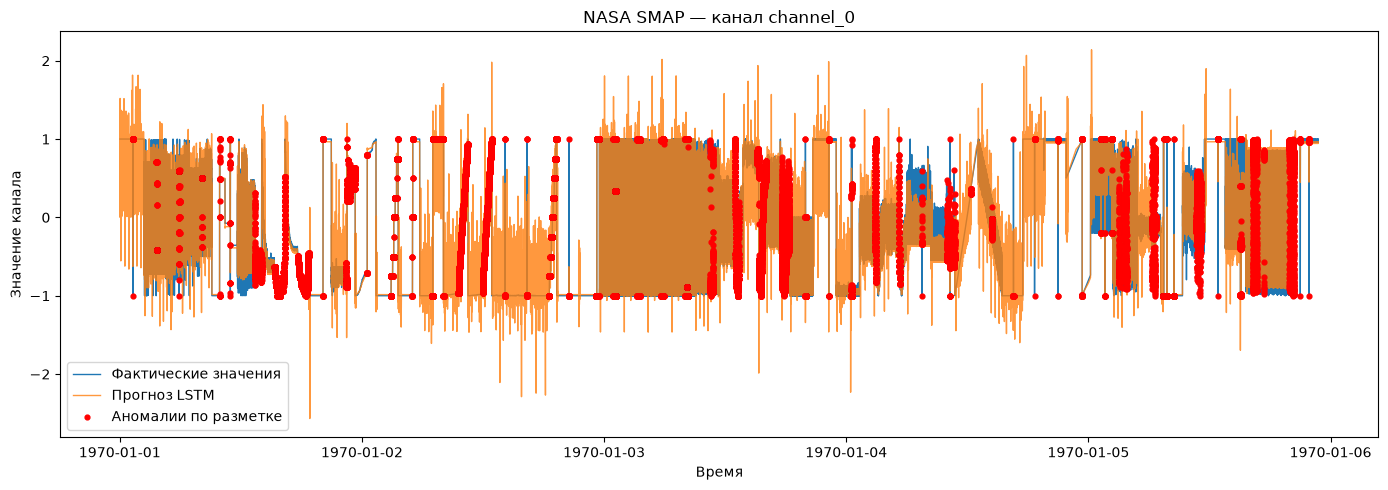

,time,actual,predicted,absolute_error,is_anomaly
0,1970-01-01 00:01:40,1.0,0.965178,0.034822,False
1,1970-01-01 00:01:41,1.0,0.965178,0.034822,False
2,1970-01-01 00:01:42,1.0,0.965178,0.034822,False
3,1970-01-01 00:01:43,1.0,0.965178,0.034822,False
4,1970-01-01 00:01:44,1.0,0.965178,0.034822,False
5,1970-01-01 00:01:45,1.0,0.965178,0.034822,False
6,1970-01-01 00:01:46,1.0,0.965178,0.034822,False
7,1970-01-01 00:01:47,1.0,0.965178,0.034822,False
8,1970-01-01 00:01:48,1.0,0.965177,0.034823,False
9,1970-01-01 00:01:49,1.0,0.965177,0.034823,False


In [9]:
feature = 0
times = pd.to_datetime(prepared.test_target_time, unit='ms', errors='coerce')
anomalies = prepared.test_anomaly_mask

plt.figure(figsize=(14, 5))
plt.plot(times, actual[:, feature], label='Фактические значения', linewidth=1)
plt.plot(times, predicted[:, feature], label='Прогноз LSTM', alpha=0.8, linewidth=1)
plt.scatter(
    times[anomalies], actual[anomalies, feature],
    s=12, color='red', label='Аномалии по разметке', zorder=3,
)
plt.title(f'NASA SMAP — канал {prepared.feature_names[feature]}')
plt.xlabel('Время')
plt.ylabel('Значение канала')
plt.legend()
plt.tight_layout()
plt.savefig(results_dir / 'test_forecast.png', dpi=150)
plt.show()

sample = pd.DataFrame({
    'time': times[:10],
    'actual': actual[:10, feature],
    'predicted': predicted[:10, feature],
    'absolute_error': np.abs(actual[:10, feature] - predicted[:10, feature]),
    'is_anomaly': anomalies[:10],
})
display(sample)

## Вывод

В работе подготовлен многомерный ряд NASA SMAP, сформированы пары «история из 100 шагов → следующий шаг» и обучена LSTM-регрессия. Качество прогноза на отложенном тестовом ряде оценено метриками MAE и RMSE. График позволяет визуально сравнить прогноз с телеметрией и увидеть размеченные аномальные интервалы.

Результаты сохраняются в папку `results`: лучшая модель `best_model.keras`, метрики `test_metrics.csv`, графики `training_loss.png` и `test_forecast.png`.